In [ ]:
import numpy as np

# ---------- DATOS DEL PROBLEMA ----------
N_SATELITES = 8
RADIO_REGION_KM = 300
RADIO_TIERRA_KM = 6371.0

REGIONES = [
    {"nombre": "Península de Yucatán", "lat": 20.5,  "lon": -89.0,  "prioridad": "Alta"},
    {"nombre": "Amazonía brasileña",   "lat": -3.5,  "lon": -62.0,  "prioridad": "Alta"},
    {"nombre": "California",           "lat": 36.8,  "lon": -119.4, "prioridad": "Media"},
    {"nombre": "Sahel",                "lat": 15.0,  "lon": 0.0,    "prioridad": "Media"},
    {"nombre": "Japón",                "lat": 36.0,  "lon": 138.0,  "prioridad": "Media"},
    {"nombre": "Interior de Australia","lat": -25.0, "lon": 133.0,  "prioridad": "Normal"},
]

ZONAS_DESECHOS = [
    {"nombre": "Atlántico Norte", "lat": 45.0,  "lon": -35.0,  "radio_grados": 12},
    {"nombre": "Pacífico Sur",    "lat": -30.0, "lon": -120.0, "radio_grados": 10},
    {"nombre": "Región polar norte", "lat": 78.0, "lon": 30.0, "radio_grados": 8},
]

OBJETOS_OCUPADOS = [
    {"nombre": "Objeto A", "lat": 10.0,  "lon": 45.0,  "radio_grados": 5},
    {"nombre": "Objeto B", "lat": -15.0, "lon": 110.0, "radio_grados": 5},
]

# ---------- GEOMETRÍA ----------
def distancia_angular(lat1, lon1, lat2, lon2):
    """Distancia entre dos puntos de la esfera, en grados (fórmula de haversine)."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return np.degrees(2 * np.arcsin(np.sqrt(np.clip(a, 0, 1))))

def grados_a_km(grados):
    return np.radians(grados) * RADIO_TIERRA_KM

def zona_que_invade(lat, lon):
    """Devuelve el nombre de la zona prohibida donde cae el punto, o None si es válido."""
    for zona in ZONAS_DESECHOS + OBJETOS_OCUPADOS:
        if distancia_angular(lat, lon, zona["lat"], zona["lon"]) <= zona["radio_grados"]:
            return zona["nombre"]
    return None

# ---------- PRUEBAS ----------
print("0° a 90° en el ecuador:", distancia_angular(0, 0, 0, 90))        # esperado 90
print("Puntos opuestos:", distancia_angular(0, 0, 0, 180))              # esperado 180
print("Polo norte a polo sur:", distancia_angular(90, 0, -90, 0))       # esperado 180
print("Mismo punto:", distancia_angular(20.5, -89, 20.5, -89))          # esperado 0
print("1 grado en km:", grados_a_km(1))                                 # esperado ~111.2
print("Punto (45,-35):", zona_que_invade(45, -35))                      # esperado Atlántico Norte
print("Punto (10,45):", zona_que_invade(10, 45))                        # esperado Objeto A
print("Punto (0,0):", zona_que_invade(0, 0))                            # esperado None

0° a 90° en el ecuador: 89.99999999999999
Puntos opuestos: 180.0
Polo norte a polo sur: 180.0
Mismo punto: 0.0
1 grado en km: 111.19492664455873
Punto (45,-35): Atlántico Norte
Punto (10,45): Objeto A
Punto (0,0): None


In [ ]:
# ---------- MODELO DE COBERTURA ----------
PESOS = {"Alta": 3, "Media": 2, "Normal": 1}
R_COB_GRADOS = 10.0                                   # radio de la huella de cada satélite
RADIO_REGION_GRADOS = np.degrees(RADIO_REGION_KM / RADIO_TIERRA_KM)  # 300 km ≈ 2.7°
PESO_TOTAL = sum(PESOS[r["prioridad"]] for r in REGIONES)

def crear_configuracion_aleatoria(rng):
    """Matriz (8, 2) con [lat, lon] por satélite, distribuidos uniformemente en la esfera."""
    lat = np.degrees(np.arcsin(rng.uniform(-1, 1, N_SATELITES)))
    lon = rng.uniform(-180, 180, N_SATELITES)
    return np.column_stack((lat, lon))

def regiones_cubiertas(config):
    """Lista de 6 booleanos: True si la región está cubierta por algún satélite."""
    cubiertas = []
    for r in REGIONES:
        d = distancia_angular(r["lat"], r["lon"], config[:, 0], config[:, 1])
        cubiertas.append(bool(np.any(d + RADIO_REGION_GRADOS <= R_COB_GRADOS)))
    return cubiertas

def cobertura_ponderada(config):
    """Fracción (0 a 1) del peso total de las regiones que quedó cubierta."""
    cub = regiones_cubiertas(config)
    peso = sum(PESOS[r["prioridad"]] for r, c in zip(REGIONES, cub) if c)
    return peso / PESO_TOTAL

# ---------- PRUEBAS ----------
print("Radio región en grados:", RADIO_REGION_GRADOS, "(esperado ~2.70)")
print("Peso total:", PESO_TOTAL, "(esperado 13)")

# Prueba 1: un satélite en el centro de cada región + 2 sobrantes
centros = [[r["lat"], r["lon"]] for r in REGIONES]
config_perfecta = np.array(centros + [[0, 0], [0, 0]])
print("Perfecta ->", regiones_cubiertas(config_perfecta), cobertura_ponderada(config_perfecta))  # todas True, 1.0

# Prueba 2: solo las dos regiones Alta (Yucatán y Amazonía)
config_alta = np.array(centros[:2] + [[0, 0]] * 6)
print("Solo Alta ->", regiones_cubiertas(config_alta), cobertura_ponderada(config_alta))  # 6/13 = 0.4615

# Prueba 3: satélite a 12° de Yucatán (fuera de la huella de 10°)
config_lejos = np.array([[32.5, -89.0]] + [[0, 0]] * 7)
print("A 12° ->", regiones_cubiertas(config_lejos)[0], "(esperado False)")

# Prueba 4: satélite a 6° de Yucatán (dentro)
config_cerca = np.array([[26.5, -89.0]] + [[0, 0]] * 7)
print("A 6° ->", regiones_cubiertas(config_cerca)[0], "(esperado True)")

# Prueba 5: configuración aleatoria (semilla fija para que sea repetible)
rng = np.random.default_rng(42)
config_azar = crear_configuracion_aleatoria(rng)
print("Aleatoria:\n", np.round(config_azar, 1))
print("Cobertura aleatoria:", cobertura_ponderada(config_azar))

Radio región en grados: 2.697964817756192 (esperado ~2.70)
Peso total: 13 (esperado 13)
Perfecta -> [True, True, True, True, True, True] 1.0
Solo Alta -> [True, True, False, False, False, False] 0.46153846153846156
A 12° -> False (esperado False)
A 6° -> True (esperado True)
Aleatoria:
 [[  33.2 -133.9]
 [  -7.   -17.9]
 [  45.8  -46.5]
 [  23.2  153.6]
 [ -54.3   51.8]
 [  72.   116.2]
 [  31.5  -20.4]
 [  34.9  -98.2]]
Cobertura aleatoria: 0.0


In [ ]:
# ---------- VALIDEZ Y FITNESS ----------
ZONAS_PROHIBIDAS = ZONAS_DESECHOS + OBJETOS_OCUPADOS

def violaciones(config):
    """Lista de (índice_satélite, nombre_zona, profundidad_normalizada) por cada invasión.
    La profundidad va de 0 (justo en el borde) a 1 (en el centro de la zona)."""
    lista = []
    for i, (lat, lon) in enumerate(config):
        for zona in ZONAS_PROHIBIDAS:
            d = distancia_angular(lat, lon, zona["lat"], zona["lon"])
            if d <= zona["radio_grados"]:
                profundidad = (zona["radio_grados"] - d) / zona["radio_grados"]
                lista.append((i, zona["nombre"], float(profundidad)))
    return lista

def es_valida(config):
    return len(violaciones(config)) == 0

def fitness(config):
    """Válida: cobertura (0 a 1). Inválida: siempre negativa, más negativa si invade más."""
    cobertura = cobertura_ponderada(config)
    viol = violaciones(config)
    if not viol:
        return cobertura
    return cobertura - 1.0 - sum(p for _, _, p in viol)

# ---------- PRUEBAS ----------
# Prueba 1: la configuración aleatoria del paso anterior (satélite 2 en el Atlántico Norte)
print("Aleatoria -> violaciones:", violaciones(config_azar))
print("Aleatoria -> válida:", es_valida(config_azar), "| fitness:", fitness(config_azar))
# esperado: 1 violación, índice 2, 'Atlántico Norte', profundidad ~0.33; fitness ~ -1.33

# Prueba 2: la configuración perfecta del paso anterior
print("Perfecta -> válida:", es_valida(config_perfecta), "| fitness:", fitness(config_perfecta))
# esperado: True, 1.0

# Prueba 3: cubre las 2 regiones Alta pero un satélite está en el centro del Objeto A
config_choque = np.array(centros[:2] + [[10, 45]] + [[0, 0]] * 5)
print("Choque -> violaciones:", violaciones(config_choque))
print("Choque -> fitness:", fitness(config_choque))
# esperado: 'Objeto A', profundidad 1.0; fitness ~ 0.4615 - 1 - 1 = -1.5385

# Prueba 4: satélite justo fuera del Objeto A (10°, 52°)
config_borde = np.array([[10, 52]] + [[0, 0]] * 7)
print("Fuera del borde -> válida:", es_valida(config_borde))   # esperado True

# Prueba 5: una inválida que cubre MÁS no debe ganarle a una válida que cubre MENOS
valida_poca = np.array(centros[:1] + [[0, 0]] * 7)              # solo Yucatán (3/13)
print("Válida poca cobertura:", fitness(valida_poca), "(esperado 0.2308)")
print("Inválida mucha cobertura:", fitness(config_choque), "(debe ser menor)")

Aleatoria -> violaciones: [(2, 'Atlántico Norte', 0.32360887646575076)]
Aleatoria -> válida: False | fitness: -1.3236088764657508
Perfecta -> válida: True | fitness: 1.0
Choque -> violaciones: [(2, 'Objeto A', 1.0)]
Choque -> fitness: -1.5384615384615383
Fuera del borde -> válida: True
Válida poca cobertura: 0.23076923076923078 (esperado 0.2308)
Inválida mucha cobertura: -1.5384615384615383 (debe ser menor)


In [ ]:
# ---------- PARÁMETROS DEL ALGORITMO ----------
PARAMS = {
    "tam_poblacion": 60,
    "k_torneo": 3,
    "p_mutacion": 0.25,      # probabilidad de mover cada satélite
    "sigma_grados": 5.0,     # tamaño típico del movimiento
    "p_reinicio": 0.05,      # probabilidad de reubicar un satélite al azar
}

# ---------- OPERADORES ----------
def crear_poblacion(rng, tam):
    """Array (tam, 8, 2): tam configuraciones aleatorias."""
    return np.array([crear_configuracion_aleatoria(rng) for _ in range(tam)])

def seleccion_torneo(poblacion, fits, rng, k):
    """Elige k al azar y devuelve (una copia de) la de mayor fitness."""
    idx = rng.integers(0, len(poblacion), k)
    ganador = idx[np.argmax(fits[idx])]
    return poblacion[ganador].copy()

def cruce(padre_a, padre_b, rng):
    """Cruce uniforme: cada satélite viene del padre A o del B."""
    desde_a = rng.random(N_SATELITES) < 0.5
    return np.where(desde_a[:, None], padre_a, padre_b)

def mutar(config, rng, p_mut, sigma, p_reinicio):
    """Mueve algunos satélites con ruido y reubica al azar a otros pocos."""
    nueva = config.copy()
    mover = rng.random(N_SATELITES) < p_mut
    ruido = rng.normal(0, sigma, (N_SATELITES, 2))
    nueva[mover] += ruido[mover]
    reiniciar = rng.random(N_SATELITES) < p_reinicio
    if reiniciar.any():
        nueva[reiniciar] = crear_configuracion_aleatoria(rng)[reiniciar]
    nueva[:, 0] = np.clip(nueva[:, 0], -90, 90)           # latitud dentro de rango
    nueva[:, 1] = ((nueva[:, 1] + 180) % 360) - 180       # longitud da la vuelta
    return nueva

# ---------- PRUEBAS ----------
rng = np.random.default_rng(1)

# Prueba 1: forma y rangos de la población
pob = crear_poblacion(rng, PARAMS["tam_poblacion"])
print("Forma población:", pob.shape, "(esperado (60, 8, 2))")
print("Lat en [-90,90]:", pob[:, :, 0].min() >= -90 and pob[:, :, 0].max() <= 90)
print("Lon en [-180,180]:", pob[:, :, 1].min() >= -180 and pob[:, :, 1].max() <= 180)

# Prueba 2: el cruce solo usa satélites de los padres
A = np.zeros((8, 2))
B = np.ones((8, 2)) * 50
hijo = cruce(A, B, rng)
print("Hijo (lat de cada satélite):", hijo[:, 0], "(solo 0 y 50)")
print("Cruce válido:", set(hijo[:, 0]) <= {0.0, 50.0})

# Prueba 3: mutación sin probabilidad no cambia nada; con probabilidad 1 mueve todo
base = pob[0]
sin_cambio = mutar(base, rng, 0.0, 5.0, 0.0)
print("p_mut=0 igual al original:", np.allclose(base, sin_cambio))   # esperado True
con_cambio = mutar(base, rng, 1.0, 5.0, 0.0)
print("p_mut=1 todos cambian:", np.all(np.any(base != con_cambio, axis=1)))  # esperado True

# Prueba 4: mutación en los bordes del mapa respeta los rangos
borde = np.array([[89.9, 179.9]] * 8)
muta_borde = mutar(borde, rng, 1.0, 20.0, 0.0)
print("Borde -> lat OK:", np.all(np.abs(muta_borde[:, 0]) <= 90),
      "| lon OK:", np.all(np.abs(muta_borde[:, 1]) <= 180))          # esperado True, True

# Prueba 5: torneo con k = tamaño de la población devuelve al mejor
fits = np.array([fitness(c) for c in pob])
ganador = seleccion_torneo(pob, fits, rng, len(pob))
print("Torneo total elige al mejor:", np.allclose(ganador, pob[np.argmax(fits)]))  # esperado True
print("Mejor fitness de la población inicial:", fits.max())
print("Válidas en la población inicial:", int(sum(es_valida(c) for c in pob)), "de 60")

Forma población: (60, 8, 2) (esperado (60, 8, 2))
Lat en [-90,90]: True
Lon en [-180,180]: True
Hijo (lat de cada satélite): [50.  0. 50.  0. 50.  0.  0. 50.] (solo 0 y 50)
Cruce válido: True
p_mut=0 igual al original: True
p_mut=1 todos cambian: True
Borde -> lat OK: True | lon OK: True
Torneo total elige al mejor: True
Mejor fitness de la población inicial: 0.23076923076923078
Válidas en la población inicial: 46 de 60


In [ ]:
# ---------- CICLO EVOLUTIVO ----------
def evolucionar(generaciones=100, seed=0, params=PARAMS, n_elite=2, verbose=True):
    """Ejecuta el algoritmo y devuelve (mejor_config, historial, poblacion_inicial)."""
    rng = np.random.default_rng(seed)
    tam = params["tam_poblacion"]
    pob = crear_poblacion(rng, tam)
    pob_inicial = pob.copy()

    historial = {"mejor": [], "promedio": [], "validas": [], "cobertura_mejor": []}

    for gen in range(generaciones + 1):
        fits = np.array([fitness(c) for c in pob])
        i_mejor = int(np.argmax(fits))

        historial["mejor"].append(float(fits[i_mejor]))
        historial["promedio"].append(float(fits.mean()))
        historial["validas"].append(int(sum(es_valida(c) for c in pob)))
        historial["cobertura_mejor"].append(float(cobertura_ponderada(pob[i_mejor])))

        if verbose and gen % 20 == 0:
            print(f"Gen {gen:3d} | mejor {fits[i_mejor]:.4f} | prom {fits.mean():.4f} "
                  f"| válidas {historial['validas'][-1]}/{tam}")

        if gen == generaciones:
            break

        # Elitismo: los mejores pasan sin cambios
        orden = np.argsort(fits)[::-1]
        nueva = [pob[i].copy() for i in orden[:n_elite]]

        # El resto se llena con hijos
        while len(nueva) < tam:
            a = seleccion_torneo(pob, fits, rng, params["k_torneo"])
            b = seleccion_torneo(pob, fits, rng, params["k_torneo"])
            hijo = cruce(a, b, rng)
            hijo = mutar(hijo, rng, params["p_mutacion"], params["sigma_grados"], params["p_reinicio"])
            nueva.append(hijo)
        pob = np.array(nueva)

    fits = np.array([fitness(c) for c in pob])
    return pob[int(np.argmax(fits))], historial, pob_inicial

# ---------- PRUEBAS ----------
mejor, hist, pob_ini = evolucionar(generaciones=100, seed=0)

print("\nMejor configuración:\n", np.round(mejor, 2))
print("Válida:", es_valida(mejor), "| fitness:", fitness(mejor))
print("Regiones cubiertas:", regiones_cubiertas(mejor))

# Prueba 1: el elitismo garantiza que el mejor nunca empeora
mejora_monotona = all(b2 >= b1 - 1e-12 for b1, b2 in zip(hist["mejor"], hist["mejor"][1:]))
print("Mejor nunca baja:", mejora_monotona)   # esperado True

# Prueba 2: misma semilla = mismo resultado
mejor2, hist2, _ = evolucionar(generaciones=100, seed=0, verbose=False)
print("Misma semilla reproduce:", np.allclose(mejor, mejor2))   # esperado True

# Prueba 3: el historial tiene una entrada por generación (0..100)
print("Largo historial:", len(hist["mejor"]), "(esperado 101)")

Gen   0 | mejor 0.3077 | prom -0.2544 | válidas 46/60
Gen  20 | mejor 1.0000 | prom 0.7551 | válidas 60/60
Gen  40 | mejor 1.0000 | prom 0.7279 | válidas 58/60
Gen  60 | mejor 1.0000 | prom 0.7603 | válidas 60/60
Gen  80 | mejor 1.0000 | prom 0.7584 | válidas 59/60
Gen 100 | mejor 1.0000 | prom 0.7515 | válidas 59/60

Mejor configuración:
 [[  20.59   -0.39]
 [ -10.6   -61.69]
 [  23.02  -81.64]
 [  39.74 -112.85]
 [ -21.93  131.92]
 [  37.82  134.5 ]
 [  41.63 -115.71]
 [ -23.2   104.56]]
Válida: True | fitness: 1.0
Regiones cubiertas: [True, True, True, True, True, True]
Mejor nunca baja: True
Misma semilla reproduce: True
Largo historial: 101 (esperado 101)



R_COB = 10.0°
  fitness por semilla: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
  media 1.000 | desv 0.000 | min 1.000 | max 1.000
  regiones cubiertas: [6, 6, 6, 6, 6, 6, 6, 6, 6, 6]
  todas válidas: True
  gen. en que alcanzó su mejor valor: [13, 22, 46, 52, 49, 14, 37, 25, 10, 20]

R_COB = 6.0°
  fitness por semilla: [0.923 0.769 0.769 0.846 0.923 0.923 0.692 1.    0.846 0.846]
  media 0.854 | desv 0.087 | min 0.692 | max 1.000
  regiones cubiertas: [5, 4, 4, 5, 5, 5, 4, 6, 5, 5]
  todas válidas: True
  gen. en que alcanzó su mejor valor: [76, 50, 7, 31, 80, 76, 58, 100, 24, 32]

R_COB = 4.0°
  fitness por semilla: [0.538 0.769 0.462 0.385 0.538 0.308 0.538 0.615 0.385 0.615]
  media 0.515 | desv 0.129 | min 0.308 | max 0.769
  regiones cubiertas: [3, 4, 2, 2, 3, 2, 3, 4, 2, 3]
  todas válidas: True
  gen. en que alcanzó su mejor valor: [20, 75, 93, 34, 71, 21, 32, 82, 24, 74]

Mejor ejecución con R_COB=6 -> seed 7 fitness 1.0
Márgenes a zonas (grados, deben ser > 0):
  Atlántico Norte: 29.34

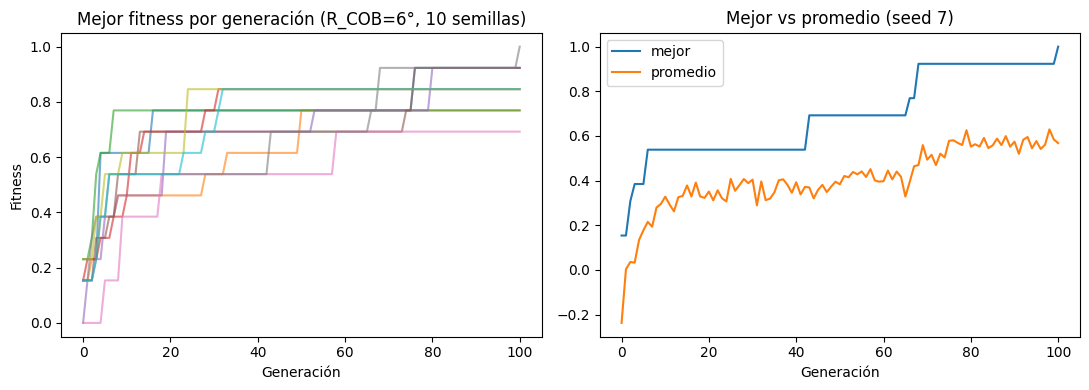

In [ ]:
import matplotlib.pyplot as plt

def ejecutar_varias(r_cob, semillas, generaciones=100):
    """Corre el algoritmo con varias semillas usando un R_COB dado. Devuelve lista de resultados."""
    global R_COB_GRADOS
    original = R_COB_GRADOS
    R_COB_GRADOS = r_cob
    resultados = []
    try:
        for s in semillas:
            mejor, hist, _ = evolucionar(generaciones=generaciones, seed=s, verbose=False)
            gen_conv = next((g for g, f in enumerate(hist["mejor"]) if f >= hist["mejor"][-1] - 1e-12), None)
            resultados.append({
                "seed": s, "fitness": fitness(mejor), "valida": es_valida(mejor),
                "cubiertas": sum(regiones_cubiertas(mejor)), "gen_final": gen_conv,
                "hist": hist, "mejor": mejor,
            })
    finally:
        R_COB_GRADOS = original
    return resultados

def distancia_minima_a_zonas(config):
    """Margen (en grados) de cada zona: distancia mínima de cualquier satélite menos el radio. >0 = respeta."""
    return {z["nombre"]: float(min(distancia_angular(lat, lon, z["lat"], z["lon"]) for lat, lon in config)
                               - z["radio_grados"]) for z in ZONAS_PROHIBIDAS}

SEMILLAS = list(range(10))

# ---------- PRUEBA A: variación entre ejecuciones, por dificultad ----------
for r_cob in (10.0, 6.0, 4.0):
    res = ejecutar_varias(r_cob, SEMILLAS)
    fits = [r["fitness"] for r in res]
    print(f"\nR_COB = {r_cob}°")
    print("  fitness por semilla:", np.round(fits, 3))
    print(f"  media {np.mean(fits):.3f} | desv {np.std(fits):.3f} | min {min(fits):.3f} | max {max(fits):.3f}")
    print("  regiones cubiertas:", [r["cubiertas"] for r in res])
    print("  todas válidas:", all(r["valida"] for r in res))
    print("  gen. en que alcanzó su mejor valor:", [r["gen_final"] for r in res])

# ---------- PRUEBA B: restricciones en la mejor solución ----------
res6 = ejecutar_varias(6.0, SEMILLAS)
mejor_res = max(res6, key=lambda r: r["fitness"])
print("\nMejor ejecución con R_COB=6 -> seed", mejor_res["seed"], "fitness", round(mejor_res["fitness"], 3))
print("Márgenes a zonas (grados, deben ser > 0):")
for nombre, margen in distancia_minima_a_zonas(mejor_res["mejor"]).items():
    print(f"  {nombre}: {margen:.2f}")

# ---------- GRÁFICA DE EVOLUCIÓN ----------
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for r in res6:
    ax[0].plot(r["hist"]["mejor"], alpha=0.6)
ax[0].set_title("Mejor fitness por generación (R_COB=6°, 10 semillas)")
ax[0].set_xlabel("Generación"); ax[0].set_ylabel("Fitness")
h = mejor_res["hist"]
ax[1].plot(h["mejor"], label="mejor"); ax[1].plot(h["promedio"], label="promedio")
ax[1].set_title(f"Mejor vs promedio (seed {mejor_res['seed']})")
ax[1].set_xlabel("Generación"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
# ---------- ESCENARIOS CON RESTRICCIONES EXTRA ----------
ZONAS_BASE = list(ZONAS_PROHIBIDAS)

def correr_escenario(nombre, zonas_extra, r_cob=6.0, semillas=SEMILLAS, generaciones=100):
    """Corre el algoritmo con zonas prohibidas adicionales y las quita al terminar."""
    global ZONAS_PROHIBIDAS
    ZONAS_PROHIBIDAS = ZONAS_BASE + list(zonas_extra)
    try:
        res = ejecutar_varias(r_cob, semillas, generaciones)
        peor_margen = min(min(distancia_minima_a_zonas(r["mejor"]).values()) for r in res)
    finally:
        ZONAS_PROHIBIDAS = ZONAS_BASE
    fits = [r["fitness"] for r in res]
    print(f"\n=== {nombre} (R_COB={r_cob}°, {len(ZONAS_BASE) + len(zonas_extra)} zonas) ===")
    print("  fitness por semilla:", np.round(fits, 3))
    print(f"  media {np.mean(fits):.3f} | desv {np.std(fits):.3f} | max {max(fits):.4f}")
    print("  regiones cubiertas:", [r["cubiertas"] for r in res])
    print("  todas válidas:", all(r["valida"] for r in res),
          "| peor margen a una zona:", round(peor_margen, 2), "° (debe ser > 0)")
    return res

# ---------- PRUEBA 1: ESPACIO REDUCIDO ----------
# Tres zonas extra pegadas a Yucatán, Japón y Australia (sin cubrir sus centros)
EXTRA_REDUCIDO = [
    {"nombre": "Extra Yucatán", "lat": 20.5, "lon": -80.0, "radio_grados": 8},
    {"nombre": "Extra Japón",   "lat": 36.0, "lon": 128.0, "radio_grados": 8},
    {"nombre": "Extra Australia", "lat": -25.0, "lon": 125.0, "radio_grados": 6},
]
res_reducido = correr_escenario("ESPACIO REDUCIDO", EXTRA_REDUCIDO)
print("  (referencia sin zonas extra, R_COB=6: media 0.854, desv 0.087)")

# ---------- PRUEBA 2: CONDICIÓN INVIABLE ----------
# Una zona de 15° sobre el centro de Yucatán: ningún satélite válido puede cubrirla
BLOQUEO = [{"nombre": "Bloqueo Yucatán", "lat": 20.5, "lon": -89.0, "radio_grados": 15}]
res_inviable = correr_escenario("CONDICIÓN INVIABLE", BLOQUEO)
techo = 1 - 3 / 13
print(f"  Techo teórico = 10/13 = {techo:.4f} (Yucatán, peso 3, no se puede cubrir)")
print("  Alguna supera el techo (sería un error):", any(r["fitness"] > techo + 1e-9 for r in res_inviable))
print("  Alguna cubre Yucatán:", any(regiones_cubiertas(r["mejor"])[0] for r in res_inviable))


=== ESPACIO REDUCIDO (R_COB=6.0°, 8 zonas) ===
  fitness por semilla: [1.    0.769 0.769 0.692 0.769 0.769 0.615 1.    0.615 0.923]
  media 0.792 | desv 0.133 | max 1.0000
  regiones cubiertas: [6, 4, 4, 4, 4, 5, 4, 6, 4, 5]
  todas válidas: True | peor margen a una zona: 0.36 ° (debe ser > 0)
  (referencia sin zonas extra, R_COB=6: media 0.854, desv 0.087)

=== CONDICIÓN INVIABLE (R_COB=6.0°, 6 zonas) ===
  fitness por semilla: [0.769 0.615 0.692 0.615 0.615 0.769 0.769 0.769 0.769 0.769]
  media 0.715 | desv 0.069 | max 0.7692
  regiones cubiertas: [5, 4, 4, 4, 4, 5, 5, 5, 5, 5]
  todas válidas: True | peor margen a una zona: 0.5 ° (debe ser > 0)
  Techo teórico = 10/13 = 0.7692 (Yucatán, peso 3, no se puede cubrir)
  Alguna supera el techo (sería un error): False
  Alguna cubre Yucatán: False


In [ ]:
# ---------- PRUEBA 3: MÁS GENERACIONES ----------
res_largo = ejecutar_varias(6.0, SEMILLAS, generaciones=300)
f100 = [r["fitness"] for r in res6]
f300 = [r["fitness"] for r in res_largo]
print("100 gen:", np.round(f100, 3), f"| media {np.mean(f100):.3f}")
print("300 gen:", np.round(f300, 3), f"| media {np.mean(f300):.3f}")
print("Llegaron a 1.0 -> 100 gen:", sum(f >= 1 - 1e-9 for f in f100),
      "| 300 gen:", sum(f >= 1 - 1e-9 for f in f300))
print("Generación del mejor valor (300):", [r["gen_final"] for r in res_largo])
print("300 nunca peor que 100:", all(b >= a - 1e-9 for a, b in zip(f100, f300)))  # esperado True

# ---------- PRUEBA PROPIA: CAMBIO DE CONDICIONES ----------
def aplicar_prioridades(nuevas):
    """Cambia prioridades (dict nombre -> prioridad), recalcula el peso total y devuelve las anteriores."""
    global PESO_TOTAL
    anteriores = {r["nombre"]: r["prioridad"] for r in REGIONES}
    for r in REGIONES:
        if r["nombre"] in nuevas:
            r["prioridad"] = nuevas[r["nombre"]]
    PESO_TOTAL = sum(PESOS[r["prioridad"]] for r in REGIONES)
    return anteriores

vieja = min(res6, key=lambda r: r["fitness"])
cfg = vieja["mejor"]
cub = regiones_cubiertas(cfg)
sin_cubrir = [r["nombre"] for r, c in zip(REGIONES, cub) if not c]
print("\nConfig vieja: seed", vieja["seed"], "| fitness", round(fitness(cfg), 4), "| sin cubrir:", sin_cubrir)

# (a) Una zona deja de estar disponible: la configuración vieja sigue siendo válida
ZONAS_PROHIBIDAS = ZONAS_BASE[:-1]
print("Sin la zona 'Objeto B' -> sigue válida:", es_valida(cfg))     # esperado True
ZONAS_PROHIBIDAS = ZONAS_BASE

# (b) Las regiones sin cubrir pasan a prioridad Alta
anteriores = aplicar_prioridades({n: "Alta" for n in sin_cubrir})
try:
    print("Mismo diseño, prioridades nuevas -> válida:", es_valida(cfg),
          "| fitness:", round(fitness(cfg), 4), "(debe bajar)")
    res_nuevo = ejecutar_varias(6.0, SEMILLAS)
    fn = [r["fitness"] for r in res_nuevo]
    print("Re-optimizado (10 semillas):", np.round(fn, 3), f"| media {np.mean(fn):.3f} | max {max(fn):.3f}")
    print("Regiones cubiertas:", [r["cubiertas"] for r in res_nuevo])
finally:
    aplicar_prioridades(anteriores)
print("Prioridades restauradas, peso total:", PESO_TOTAL, "(esperado 13)")

100 gen: [0.923 0.769 0.769 0.846 0.923 0.923 0.692 1.    0.846 0.846] | media 0.854
300 gen: [1.    0.923 0.923 1.    0.923 0.923 1.    1.    1.    1.   ] | media 0.969
Llegaron a 1.0 -> 100 gen: 1 | 300 gen: 6
Generación del mejor valor (300): [137, 102, 239, 200, 80, 76, 183, 100, 160, 259]
300 nunca peor que 100: True

Config vieja: seed 6 | fitness 0.6923 | sin cubrir: ['Península de Yucatán', 'Interior de Australia']
Sin la zona 'Objeto B' -> sigue válida: True
Mismo diseño, prioridades nuevas -> válida: True | fitness: 0.6 (debe bajar)
Re-optimizado (10 semillas): [0.867 0.733 0.867 0.867 0.867 0.8   0.867 1.    1.    0.867] | media 0.873 | max 1.000
Regiones cubiertas: [5, 4, 5, 5, 5, 5, 5, 6, 6, 5]
Prioridades restauradas, peso total: 13 (esperado 13)


In [ ]:
import plotly.graph_objects as go

R_COB_GRADOS = 6.0   # escenario oficial para la visualización

# ---------- GEOMETRÍA PARA 3D ----------
def a_xyz(lat, lon, r=1.0):
    lat, lon = np.radians(lat), np.radians(lon)
    return (r * np.cos(lat) * np.cos(lon), r * np.cos(lat) * np.sin(lon), r * np.sin(lat))

def circulo(lat, lon, radio_grados, r=1.0, n=60):
    """Puntos de un círculo de radio angular dado sobre la esfera."""
    lat0, lon0, d = np.radians(lat), np.radians(lon), np.radians(radio_grados)
    b = np.linspace(0, 2 * np.pi, n)
    lat2 = np.arcsin(np.sin(lat0) * np.cos(d) + np.cos(lat0) * np.sin(d) * np.cos(b))
    lon2 = lon0 + np.arctan2(np.sin(b) * np.sin(d) * np.cos(lat0), np.cos(d) - np.sin(lat0) * np.sin(lat2))
    return a_xyz(np.degrees(lat2), np.degrees(lon2), r)

def con_cortes(lista_de_curvas):
    """Une varias curvas (x, y, z) en una sola traza separándolas con None."""
    xs, ys, zs = [], [], []
    for x, y, z in lista_de_curvas:
        xs += list(x) + [None]; ys += list(y) + [None]; zs += list(z) + [None]
    return xs, ys, zs

# ---------- ELEMENTOS ESTÁTICOS ----------
def trazas_estaticas():
    trazas = []
    u, v = np.meshgrid(np.linspace(0, 2 * np.pi, 80), np.linspace(-np.pi / 2, np.pi / 2, 40))
    trazas.append(go.Surface(x=np.cos(v) * np.cos(u), y=np.cos(v) * np.sin(u), z=np.sin(v),
                             surfacecolor=np.zeros_like(u), colorscale=[[0, "#cfe3f2"], [1, "#cfe3f2"]],
                             showscale=False, hoverinfo="skip", lighting=dict(ambient=0.9), name="Tierra"))
    # cuadrícula cada 30°
    curvas = []
    for lat in range(-60, 90, 30):
        lons = np.linspace(-180, 180, 100)
        curvas.append(a_xyz(np.full(100, lat), lons, 1.002))
    for lon in range(-180, 180, 30):
        lats = np.linspace(-90, 90, 100)
        curvas.append(a_xyz(lats, np.full(100, lon), 1.002))
    x, y, z = con_cortes(curvas)
    trazas.append(go.Scatter3d(x=x, y=y, z=z, mode="lines", line=dict(color="#7a8fa3", width=1),
                               hoverinfo="skip", name="Cuadrícula 30°", showlegend=False))
    # zonas prohibidas rellenas
    for zona, color in [(z, "red") for z in ZONAS_DESECHOS] + [(z, "purple") for z in OBJETOS_OCUPADOS]:
        xc, yc, zc = circulo(zona["lat"], zona["lon"], zona["radio_grados"], r=1.012)
        cx, cy, cz = a_xyz(zona["lat"], zona["lon"], 1.012)
        n = len(xc)
        trazas.append(go.Mesh3d(x=[cx] + list(xc), y=[cy] + list(yc), z=[cz] + list(zc),
                                i=[0] * (n - 1), j=list(range(1, n)), k=list(range(2, n + 1)),
                                color=color, opacity=0.4, name=zona["nombre"], hoverinfo="name",
                                showlegend=True))
    # círculos de 300 km de cada región
    x, y, z = con_cortes([circulo(r["lat"], r["lon"], RADIO_REGION_GRADOS, r=1.006) for r in REGIONES])
    trazas.append(go.Scatter3d(x=x, y=y, z=z, mode="lines", line=dict(color="black", width=3),
                               hoverinfo="skip", name="Radio de 300 km", showlegend=False))
    return trazas

# ---------- ELEMENTOS DE UNA CONFIGURACIÓN (siempre 5 trazas) ----------
def trazas_config(cfg, etiqueta, color):
    cub = regiones_cubiertas(cfg)
    x, y, z = con_cortes([circulo(la, lo, R_COB_GRADOS, r=1.004) for la, lo in cfg])
    huellas = go.Scatter3d(x=x, y=y, z=z, mode="lines", line=dict(color=color, width=4),
                           hoverinfo="skip", name=f"Huella {etiqueta}")
    x, y, z = con_cortes([(np.array([a, b]), np.array([c, d]), np.array([e, f]))
                          for (a, c, e), (b, d, f) in
                          [(a_xyz(la, lo, 1.0), a_xyz(la, lo, 1.15)) for la, lo in cfg]])
    lineas = go.Scatter3d(x=x, y=y, z=z, mode="lines", line=dict(color=color, width=2),
                          hoverinfo="skip", showlegend=False)
    sx, sy, sz = a_xyz(cfg[:, 0], cfg[:, 1], 1.15)
    sats = go.Scatter3d(x=sx, y=sy, z=sz, mode="markers+text", text=[f"S{i+1}" for i in range(len(cfg))],
                        marker=dict(size=6, color=color), name=f"Satélites {etiqueta}",
                        hovertext=[f"S{i+1}: {la:.1f}°, {lo:.1f}°" for i, (la, lo) in enumerate(cfg)],
                        hoverinfo="text")
    def regiones(mascara, simbolo, col, nombre):
        rs = [r for r, m in zip(REGIONES, mascara) if m]
        px, py, pz = a_xyz(np.array([r["lat"] for r in rs]), np.array([r["lon"] for r in rs]), 1.015)
        return go.Scatter3d(x=px, y=py, z=pz, mode="markers+text", text=[r["nombre"] for r in rs],
                            textposition="top center", marker=dict(size=7, color=col, symbol=simbolo),
                            name=nombre, hoverinfo="text", hovertext=[r["nombre"] for r in rs])
    cubiertas = regiones(cub, "diamond", "limegreen", f"Región cubierta ({etiqueta})")
    no_cubiertas = regiones([not c for c in cub], "x", "black", f"Región NO cubierta ({etiqueta})")
    return [huellas, lineas, sats, cubiertas, no_cubiertas]

# ---------- DATOS REALES DE LA EJECUCIÓN ----------
mejor_run = max(res_largo, key=lambda r: r["fitness"])
sem = mejor_run["seed"]
mejor, hist, pob_ini = evolucionar(generaciones=300, seed=sem, verbose=False)
inicial = pob_ini[int(np.argmax([fitness(c) for c in pob_ini]))]

print(f"Semilla {sem}")
print(f"Inicial -> fitness {fitness(inicial):.4f} | válida {es_valida(inicial)} | cubre {sum(regiones_cubiertas(inicial))}/6")
print(f"Final   -> fitness {fitness(mejor):.4f} | válida {es_valida(mejor)} | cubre {sum(regiones_cubiertas(mejor))}/6")

# Prueba de consistencia: la geometría 3D coincide con la usada en el algoritmo
def angulo_xyz(lat1, lon1, lat2, lon2):
    a, b = np.array(a_xyz(lat1, lon1)), np.array(a_xyz(lat2, lon2))
    return np.degrees(np.arccos(np.clip(a @ b, -1, 1)))

dif = max(abs(angulo_xyz(r["lat"], r["lon"], la, lo) - distancia_angular(r["lat"], r["lon"], la, lo))
          for r in REGIONES for la, lo in mejor)
print("Diferencia máxima entre ángulo 3D y haversine (grados):", f"{dif:.2e}", "(esperado < 1e-3)")
print("Final coincide con la ejecución guardada:", np.allclose(mejor, mejor_run["mejor"]))  # esperado True

# ---------- FIGURA ----------
fig = go.Figure()
for t in trazas_estaticas():
    fig.add_trace(t)
n_est = len(fig.data)
for t in trazas_config(inicial, "inicial", "darkorange"):
    fig.add_trace(t)
for t in trazas_config(mejor, "final", "royalblue"):
    fig.add_trace(t)

vis_inicial = [True] * n_est + [True] * 5 + [False] * 5
vis_final = [True] * n_est + [False] * 5 + [True] * 5
for t, v in zip(fig.data, vis_final):
    t.visible = v

fig.update_layout(
    title=f"AstroShield: R_COB = {R_COB_GRADOS:.0f}°, semilla {sem} | inicial {fitness(inicial):.3f} → final {fitness(mejor):.3f}",
    scene=dict(aspectmode="data", xaxis_visible=False, yaxis_visible=False, zaxis_visible=False),
    updatemenus=[dict(type="buttons", direction="right", x=0.02, y=1.0, buttons=[
        dict(label="Inicial", method="update", args=[{"visible": vis_inicial}]),
        dict(label="Final", method="update", args=[{"visible": vis_final}]),
    ])],
    height=720, margin=dict(l=0, r=0, t=60, b=0),
)
fig.write_html("astroshield_globo.html")
fig.show()

Semilla 0
Inicial -> fitness 0.2308 | válida True | cubre 1/6
Final   -> fitness 1.0000 | válida True | cubre 6/6
Diferencia máxima entre ángulo 3D y haversine (grados): 4.54e-13 (esperado < 1e-3)
Final coincide con la ejecución guardada: True


In [ ]:
import json, urllib.request
from PIL import Image, ImageDraw

# ---------- 1. DESCARGAR EL MAPA DE CONTINENTES ----------
URL_TIERRA = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_land.geojson"
try:
    with urllib.request.urlopen(URL_TIERRA, timeout=30) as f:
        tierra = json.load(f)
    print("Mapa descargado:", len(tierra["features"]), "elementos de tierra")
except Exception as e:
    tierra = None
    print("No se pudo descargar el mapa:", e, "-> se usará la Tierra lisa")

# ---------- 2. TEXTURA: MÁSCARA TIERRA / OCÉANO ----------
W, H = 1440, 720   # resolución de la máscara (0.25° por píxel)

def poligonos(geojson):
    """Lista de polígonos; cada uno es una lista de anillos [(lon, lat), ...]."""
    salida = []
    for feat in geojson["features"]:
        g = feat["geometry"]
        if g["type"] == "Polygon":
            salida.append(g["coordinates"])
        elif g["type"] == "MultiPolygon":
            salida.extend(g["coordinates"])
    return salida

def mascara_tierra(polis):
    """Matriz booleana (H, W): True donde hay tierra."""
    img = Image.new("L", (W, H), 0)
    d = ImageDraw.Draw(img)
    for p in polis:
        for k, anillo in enumerate(p):      # el primer anillo es el borde, los demás son huecos (lagos)
            pts = [((lo + 180) / 360 * (W - 1), (90 - la) / 180 * (H - 1)) for lo, la in anillo]
            d.polygon(pts, fill=255 if k == 0 else 0)
    return np.array(img) > 0

def es_tierra(mask, lat, lon):
    return bool(mask[int(round((90 - lat) / 180 * (H - 1))), int(round((lon + 180) / 360 * (W - 1)))])

def superficie_con_textura(mask):
    lon = np.linspace(-180, 180, 361)
    lat = np.linspace(-90, 90, 181)
    LON, LAT = np.meshgrid(lon, lat)
    col = np.round((LON + 180) / 360 * (W - 1)).astype(int)
    fila = np.round((90 - LAT) / 180 * (H - 1)).astype(int)
    hay_tierra = mask[fila, col]
    valor = np.where(hay_tierra, np.where(np.abs(LAT) >= 68, 2, 1), 0)   # 0 océano, 1 tierra, 2 hielo
    x, y, z = a_xyz(LAT, LON)
    escala = [[0, "#14407a"], [0.25, "#14407a"], [0.25, "#3c8d4f"],
              [0.75, "#3c8d4f"], [0.75, "#eef4f8"], [1, "#eef4f8"]]
    return go.Surface(x=x, y=y, z=z, surfacecolor=valor, colorscale=escala, cmin=0, cmax=2,
                      showscale=False, hoverinfo="skip",
                      lighting=dict(ambient=0.85, diffuse=0.4, specular=0.05), name="Tierra")

def costas(polis):
    curvas = []
    for p in polis:
        lo = np.array([a[0] for a in p[0]])
        la = np.array([a[1] for a in p[0]])
        curvas.append(a_xyz(la, lo, 1.003))
    x, y, z = con_cortes(curvas)
    return go.Scatter3d(x=x, y=y, z=z, mode="lines", line=dict(color="rgba(255,255,255,0.7)", width=1.5),
                        hoverinfo="skip", showlegend=False, name="Costas")

# ---------- 3. FONDO DE GALAXIA ----------
rng_cielo = np.random.default_rng(7)

def estrellas():
    rng = rng_cielo
    def en_esfera(n, rmin, rmax):
        v = rng.normal(size=(n, 3))
        v /= np.linalg.norm(v, axis=1, keepdims=True)
        return v * rng.uniform(rmin, rmax, (n, 1))
    # banda de la Vía Láctea: un círculo máximo inclinado con algo de dispersión
    normal = np.array([0.35, -0.45, 0.82]); normal /= np.linalg.norm(normal)
    e1 = np.cross(normal, [0, 0, 1.0]); e1 /= np.linalg.norm(e1)
    e2 = np.cross(normal, e1)
    def banda(n, ancho):
        t = rng.uniform(0, 2 * np.pi, n)
        p = np.outer(np.cos(t), e1) + np.outer(np.sin(t), e2) + rng.normal(0, ancho, (n, 1)) * normal
        p /= np.linalg.norm(p, axis=1, keepdims=True)
        return p * rng.uniform(1.9, 2.3, (n, 1))
    fondo, halo, nucleo = en_esfera(1800, 1.9, 2.3), banda(1500, 0.22), banda(2500, 0.09)
    return [
        go.Scatter3d(x=halo[:, 0], y=halo[:, 1], z=halo[:, 2], mode="markers", hoverinfo="skip", showlegend=False,
                     marker=dict(size=7, color="#5b3fa8", opacity=0.07)),
        go.Scatter3d(x=nucleo[:, 0], y=nucleo[:, 1], z=nucleo[:, 2], mode="markers", hoverinfo="skip", showlegend=False,
                     marker=dict(size=2.2, opacity=0.55, color=rng.uniform(0, 1, len(nucleo)),
                                 colorscale=[[0, "#3f6fd0"], [0.5, "#8a6fe0"], [1, "#f0b8ff"]])),
        go.Scatter3d(x=fondo[:, 0], y=fondo[:, 1], z=fondo[:, 2], mode="markers", hoverinfo="skip", showlegend=False,
                     marker=dict(size=rng.uniform(1, 3.2, len(fondo)), opacity=0.9,
                                 color=rng.choice(["#ffffff", "#cfe0ff", "#fff1c9"], len(fondo)))),
    ]

# ---------- 4. ARMAR LA FIGURA ----------
base = trazas_estaticas()              # Tierra lisa, cuadrícula, zonas y círculos de 300 km
if tierra is not None:
    polis = poligonos(tierra)
    mask = mascara_tierra(polis)
    base[0] = superficie_con_textura(mask)
    base.insert(1, costas(polis))
    # Prueba: puntos conocidos deben caer donde corresponde
    for nombre, la, lo, esperado in [("Yucatán", 20.5, -89.0, True), ("Amazonía", -3.5, -62.0, True),
                                     ("Sahel", 15.0, 0.0, True), ("Japón", 36.0, 138.0, True),
                                     ("Interior Australia", -25.0, 133.0, True),
                                     ("Atlántico Norte", 45.0, -35.0, False), ("Pacífico Sur", -30.0, -120.0, False)]:
        print(f"  {nombre}: tierra={es_tierra(mask, la, lo)} (esperado {esperado})")
    print(f"  Fracción de tierra en el mapa: {mask.mean():.2f} (esperado ~0.29)")

for t in base:
    if t.name == "Cuadrícula 30°":
        t.line = dict(color="rgba(255,255,255,0.18)", width=1)
    if t.name == "Radio de 300 km":
        t.line = dict(color="white", width=3)

fig = go.Figure()
for t in estrellas() + base:
    fig.add_trace(t)
n_est = len(fig.data)
for t in trazas_config(inicial, "inicial", "darkorange"):
    fig.add_trace(t)
for t in trazas_config(mejor, "final", "royalblue"):
    fig.add_trace(t)
for t in fig.data:
    if t.name and t.name.startswith("Región NO cubierta"):
        t.marker.color = "yellow"

vis_inicial = [True] * n_est + [True] * 5 + [False] * 5
vis_final = [True] * n_est + [False] * 5 + [True] * 5
for t, v in zip(fig.data, vis_final):
    t.visible = v

eje = dict(range=[-2.5, 2.5], visible=False)
fig.update_layout(
    title=f"AstroShield: R_COB = {R_COB_GRADOS:.0f}°, semilla {sem} | inicial {fitness(inicial):.3f} → final {fitness(mejor):.3f}",
    paper_bgcolor="#03040a", font=dict(color="white"),
    scene=dict(xaxis=eje, yaxis=eje, zaxis=eje, aspectmode="cube", bgcolor="#03040a",
               camera=dict(eye=dict(x=0.5, y=0.5, z=0.3))),
    legend=dict(bgcolor="rgba(0,0,0,0.35)"),
    updatemenus=[dict(type="buttons", direction="right", x=0.02, y=1.0, bgcolor="#1a1f33",
                      font=dict(color="white"), buttons=[
        dict(label="Inicial", method="update", args=[{"visible": vis_inicial}]),
        dict(label="Final", method="update", args=[{"visible": vis_final}]),
    ])],
    height=720, margin=dict(l=0, r=0, t=60, b=0),
)
fig.write_html("astroshield_globo.html")
fig.show()

Mapa descargado: 127 elementos de tierra
  Yucatán: tierra=True (esperado True)
  Amazonía: tierra=True (esperado True)
  Sahel: tierra=True (esperado True)
  Japón: tierra=True (esperado True)
  Interior Australia: tierra=True (esperado True)
  Atlántico Norte: tierra=False (esperado False)
  Pacífico Sur: tierra=False (esperado False)
  Fracción de tierra en el mapa: 0.34 (esperado ~0.29)
